<>:86: SyntaxWarning: invalid escape sequence '\_'
<>:87: SyntaxWarning: invalid escape sequence '\_'
<>:91: SyntaxWarning: invalid escape sequence '\_'
<>:92: SyntaxWarning: invalid escape sequence '\_'
<>:86: SyntaxWarning: invalid escape sequence '\_'
<>:87: SyntaxWarning: invalid escape sequence '\_'
<>:91: SyntaxWarning: invalid escape sequence '\_'
<>:92: SyntaxWarning: invalid escape sequence '\_'
/tmp/ipykernel_9626/589979668.py:86: SyntaxWarning: invalid escape sequence '\_'
  configure_flattened_plot(axes[1], '(b) $max\_samples$', 2)
/tmp/ipykernel_9626/589979668.py:87: SyntaxWarning: invalid escape sequence '\_'
  axes[1].legend(title='$max\_samples$', loc='upper left', bbox_to_anchor=(1.01, 1), framealpha=0.9, fontsize=9)
/tmp/ipykernel_9626/589979668.py:91: SyntaxWarning: invalid escape sequence '\_'
  configure_flattened_plot(axes[2], '(c) $max\_features$', 3)
/tmp/ipykernel_9626/589979668.py:92: SyntaxWarning: invalid escape sequence '\_'
  axes[2].legend(title='$max\_fe

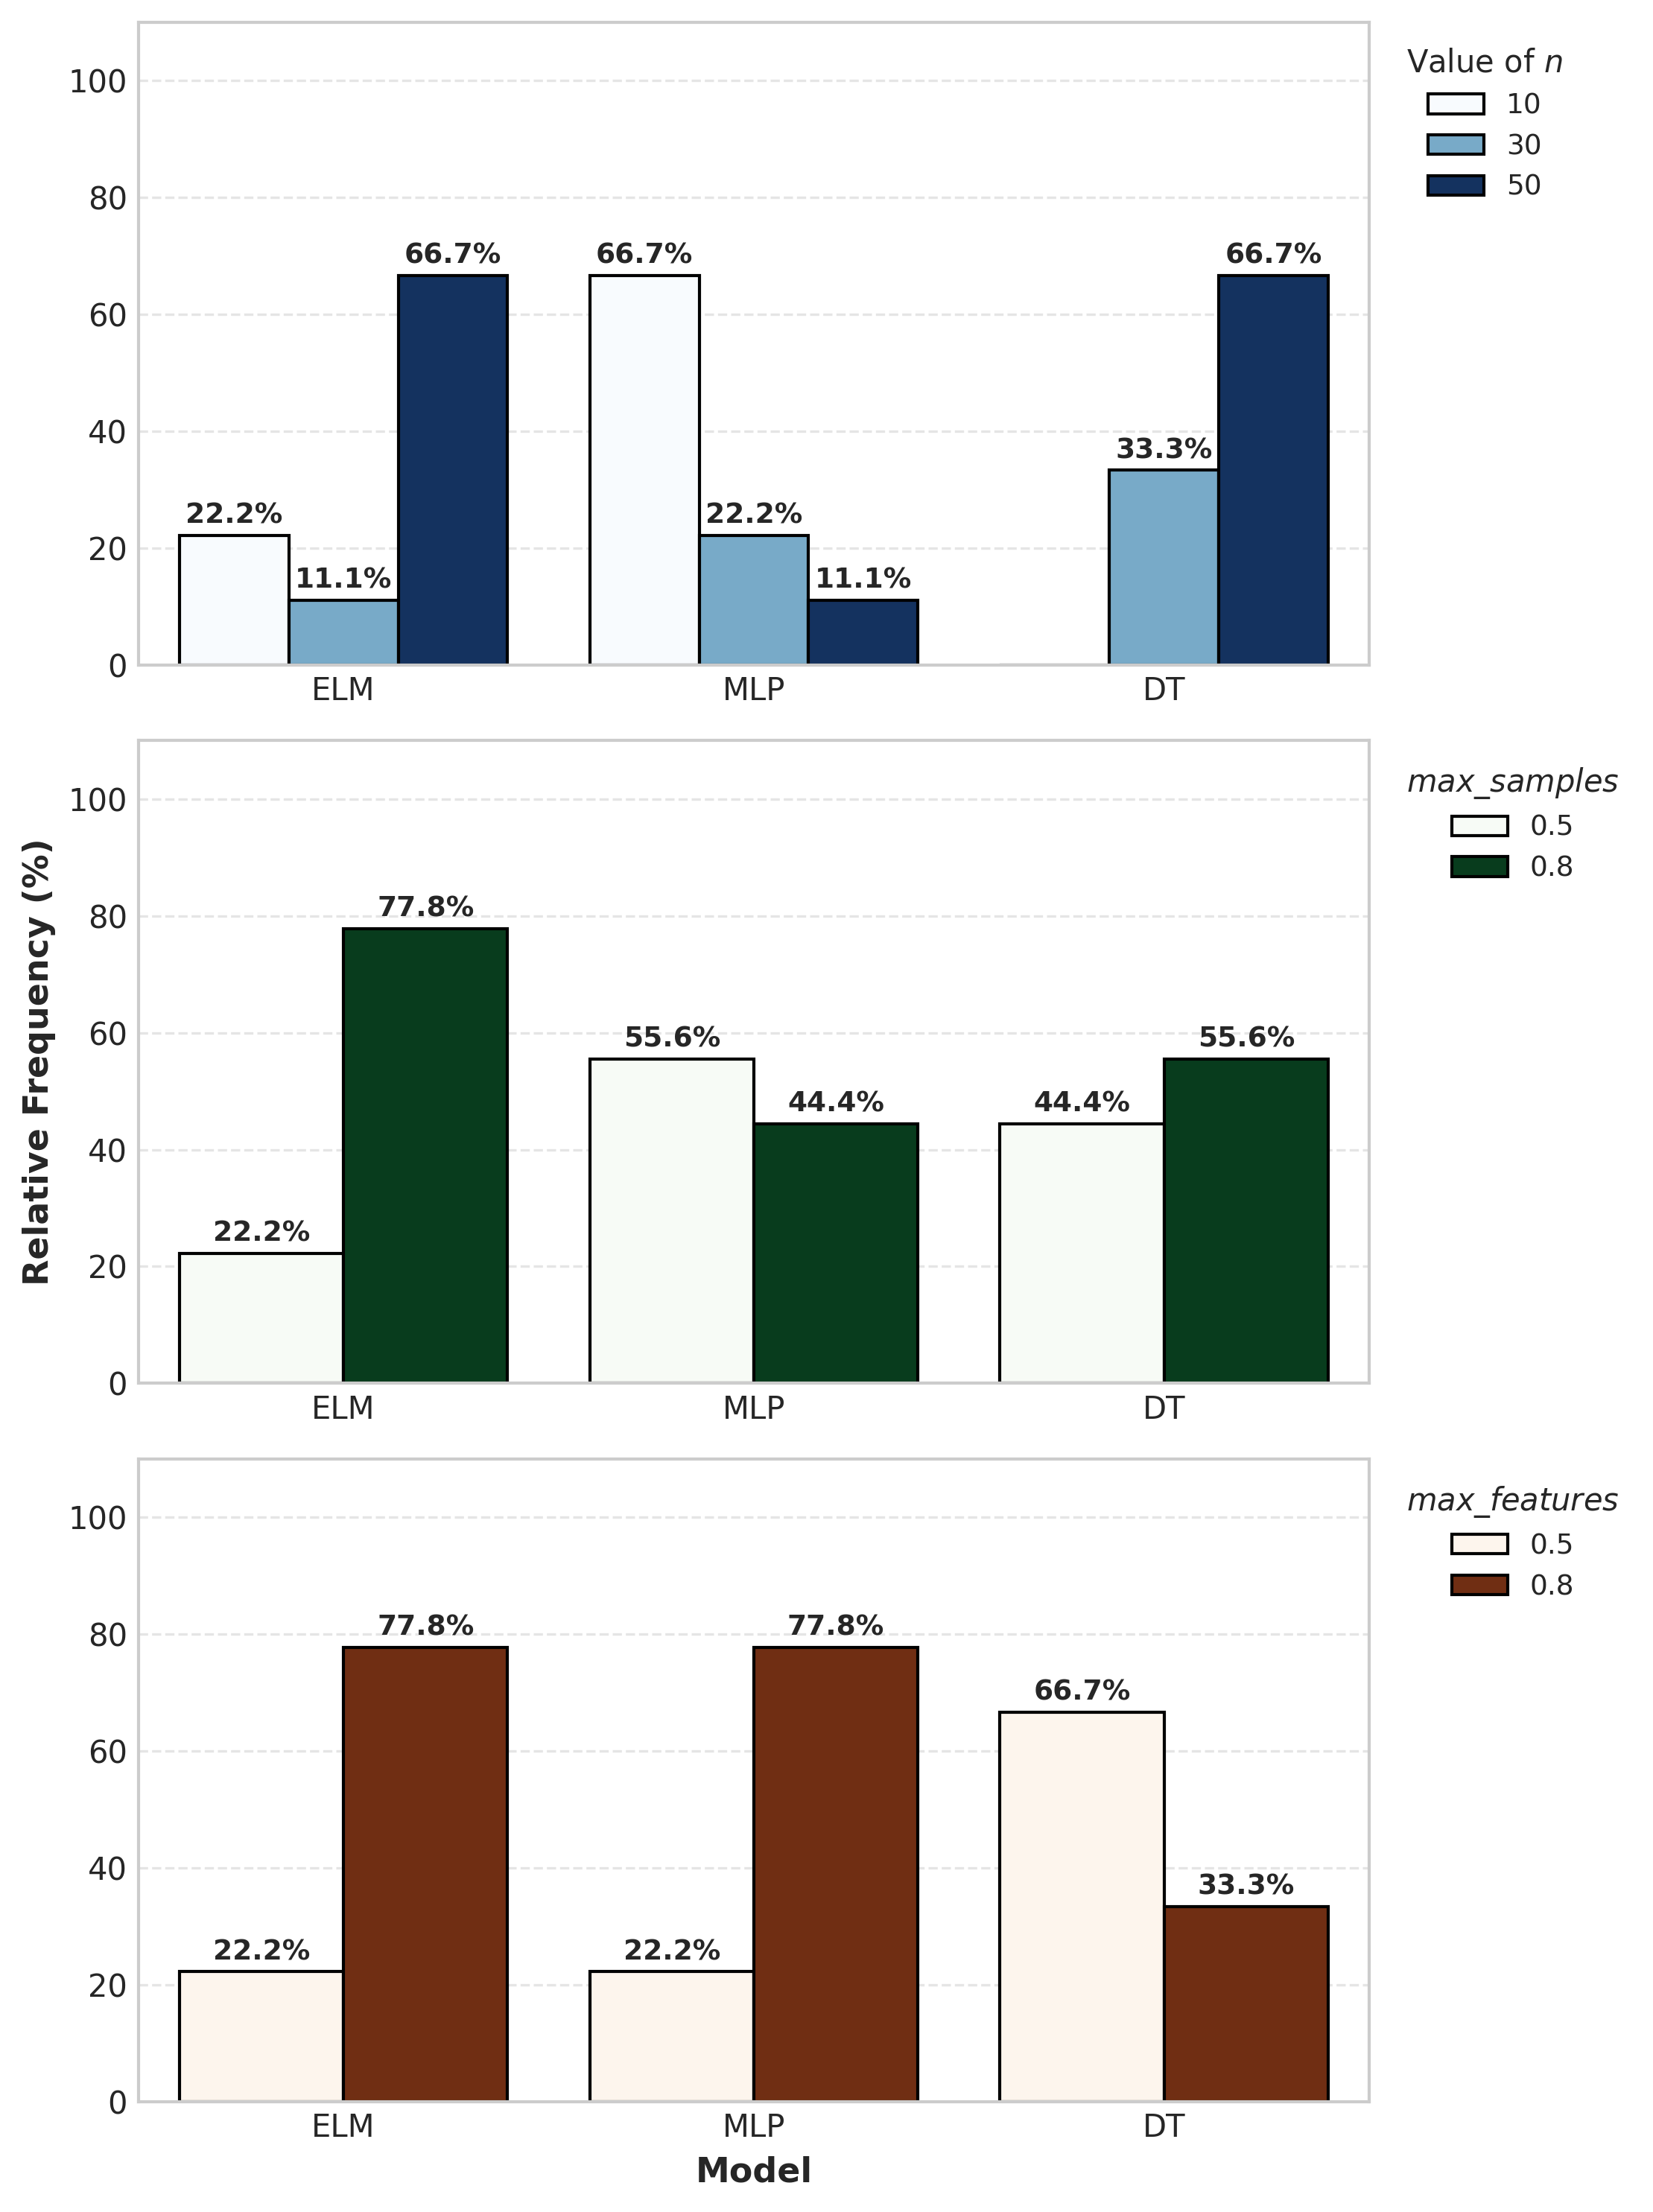

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset
data = [
    ["windspeedcamp", 24, "ELM", 30, 0.8, 0.8],
    ["windspeedcamp", 24, "MLP", 10, 0.8, 0.8],
    ["windspeedcamp", 24, "DT", 30, 0.8, 0.8],
    ["windspeedcamp", 48, "ELM", 50, 0.8, 0.8],
    ["windspeedcamp", 48, "MLP", 30, 0.5, 0.8],
    ["windspeedcamp", 48, "DT", 50, 0.8, 0.8],
    ["windspeedcamp", 72, "ELM", 50, 0.5, 0.8],
    ["windspeedcamp", 72, "MLP", 10, 0.5, 0.8],
    ["windspeedcamp", 72, "DT", 30, 0.5, 0.5],
    
    ["windspeedmace", 24, "ELM", 50, 0.8, 0.8],
    ["windspeedmace", 24, "MLP", 30, 0.5, 0.8],
    ["windspeedmace", 24, "DT", 50, 0.8, 0.5],
    ["windspeedmace", 48, "ELM", 10, 0.8, 0.8],
    ["windspeedmace", 48, "MLP", 10, 0.8, 0.8],
    ["windspeedmace", 48, "DT", 50, 0.8, 0.8],
    ["windspeedmace", 72, "ELM", 10, 0.5, 0.8],
    ["windspeedmace", 72, "MLP", 10, 0.5, 0.8],
    ["windspeedmace", 72, "DT", 50, 0.5, 0.5],
    
    ["windspeedsalva", 24, "ELM", 50, 0.8, 0.5],
    ["windspeedsalva", 24, "MLP", 10, 0.8, 0.8],
    ["windspeedsalva", 24, "DT", 50, 0.5, 0.5],
    ["windspeedsalva", 48, "ELM", 50, 0.8, 0.5],
    ["windspeedsalva", 48, "MLP", 50, 0.5, 0.5],
    ["windspeedsalva", 48, "DT", 50, 0.8, 0.5],
    ["windspeedsalva", 72, "ELM", 50, 0.8, 0.8],
    ["windspeedsalva", 72, "MLP", 10, 0.8, 0.5],
    ["windspeedsalva", 72, "DT", 30, 0.5, 0.5],
]

df = pd.DataFrame(data, columns=["Time Serie", "Horizon", "Model", "n", "max_samples", "max_features"])

# Publication quality configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12

# Layout adjusted for flattened subplots
# Decrease individual subplot height ratios
fig, axes = plt.subplots(3, 1, figsize=(7.5, 10.0), dpi=300)
models = ['ELM', 'MLP', 'DT']

# Pre-computation
def get_pct_df(col_name, val_list):
    all_comb = pd.MultiIndex.from_product([models, val_list], names=['Model', col_name]).to_frame().reset_index(drop=True)
    counts = df.groupby(['Model', col_name]).size().reset_index(name='Count')
    res = pd.merge(all_comb, counts, on=['Model', col_name], how='left').fillna(0)
    res['Percentage'] = (res['Count'] / 9.0) * 100
    return res

df_n_pct = get_pct_df('n', [10, 30, 50])
df_ms_pct = get_pct_df('max_samples', [0.5, 0.8])
df_mf_pct = get_pct_df('max_features', [0.5, 0.8])

# Formatting helper for flattened plots
def configure_flattened_plot(ax, title, id_line):
    #ax.set_title(title, fontweight='bold', pad=15)
    if id_line==2:
        ax.set_ylabel('Relative Frequency (%)', fontweight='bold')
    else:
        ax.set_ylabel('', fontweight='bold')
    if id_line ==3:
        ax.set_xlabel('Model', fontweight='bold')
    else:
        ax.set_xlabel('', fontweight='bold')
    ax.set_ylim(0, 110) # Room for annotations

# (a) Ensemble Size (n)
sns.barplot(data=df_n_pct, x='Model', y='Percentage', hue='n', ax=axes[0], palette='Blues', edgecolor='black')
configure_flattened_plot(axes[0], '(a) $n$',1)
# Legend outside: using bbox_to_anchor to position it to the right of the ax
axes[0].legend(title='Value of $n$', loc='upper left', bbox_to_anchor=(1.01, 1), framealpha=0.9, fontsize=9)

# (b) max_samples
sns.barplot(data=df_ms_pct, x='Model', y='Percentage', hue='max_samples', ax=axes[1], palette='Greens', edgecolor='black')
configure_flattened_plot(axes[1], '(b) $max\_samples$', 2)
axes[1].legend(title='$max\_samples$', loc='upper left', bbox_to_anchor=(1.01, 1), framealpha=0.9, fontsize=9)

# (c) max_features
sns.barplot(data=df_mf_pct, x='Model', y='Percentage', hue='max_features', ax=axes[2], palette='Oranges', edgecolor='black')
configure_flattened_plot(axes[2], '(c) $max\_features$', 3)
axes[2].legend(title='$max\_features$', loc='upper left', bbox_to_anchor=(1.01, 1), framealpha=0.9, fontsize=9)

# Bar Annotation > 0
for ax in axes:
    ax.grid(True, linestyle='--', alpha=0.5, axis='y')
    for p in ax.patches:
        height = p.get_height()
        if not np.isnan(height) and height > 0:
            ax.annotate(f'{height:.1f}%',
                        (p.get_x() + p.get_width() / 2., height),
                        ha='center', va='bottom',
                        fontsize=9, fontweight='bold',
                        xytext=(0, 2), textcoords='offset points')

plt.tight_layout()
# bbox_inches='tight' is crucial when legends are outside
plt.savefig('hyperparameter_vertical_flattened_legend_outside.pdf', dpi=300,  format='pdf', bbox_inches='tight')
plt.show()